yfinance 这个项目在前面「RNN 正弦波预测」的基础上，进一步学习真实时间序列预测。

我们使用 PyTorch 的 nn.RNN，根据股票过去一段时间的收盘价，预测下一个交易日的收盘价。

我建议先使用 Yahoo Finance 的历史行情数据，不必一开始就下载庞大的 Kaggle 数据集。这样可以直接通过 Python 获取数据，方便重复实验。

In [81]:
import copy
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, TensorDataset

# import warnings
# warnings.filterwarnings("ignore")

In [53]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"当前设备：{device}")

当前设备：mps


In [130]:
# 1、加载数据

import yfinance as yf

# stock_list 表示要下载哪些股票的数据
# stock_list = ['0005.HK', '0006.HK', '0066.HK', '0700.HK', '2800.HK']
stock_list = ['0005.HK']
data = yf.download(stock_list, start="2015-01-01", end="2020-02-21")
print('data fields downloaded:', set(data.columns.get_level_values(0)))
print(f"data.shape: {data.shape}")
display(data.head())
print(data.columns)
input_size = 5

# 只预测收盘价 Close
data = data.loc[:, 'Close']
print(data.columns)
display(data.head())
input_size = 1

# 只保留收盘价
# data = data[["Close"]].dropna()
data.to_csv("AAPL.csv", index=True)

# 字段	英文名称	中文含义	说明
# Open	Opening Price	开盘价	当天开盘时的价格
# High	Highest Price	最高价	当天最高成交价格
# Low	Lowest Price	最低价	当天最低成交价格
# Close	Closing Price	收盘价	当天收盘价格
# Volume	Trading Volume	成交量	当天成交的证券数量

[*********************100%***********************]  1 of 1 completed

data fields downloaded: {'Volume', 'Open', 'High', 'Low', 'Close'}
data.shape: (1267, 5)


Price,Close,High,Low,Open,Volume
Ticker,0005.HK,0005.HK,0005.HK,0005.HK,0005.HK
Date,,,,,
2015-01-02,38.562222,38.614332,38.301666,38.353776,8614012
2015-01-05,37.989010,38.223508,37.936900,38.119288,21629040
2015-01-06,37.389725,37.441835,37.181279,37.415782,35110417
2015-01-07,36.998894,37.051004,36.712281,36.738338,35378291
2015-01-08,37.103096,37.207321,36.998875,37.024933,21320949


MultiIndex([( 'Close', '0005.HK'),
            (  'High', '0005.HK'),
            (   'Low', '0005.HK'),
            (  'Open', '0005.HK'),
            ('Volume', '0005.HK')],
           names=['Price', 'Ticker'])
Index(['0005.HK'], dtype='str', name='Ticker')


Ticker,0005.HK
Date,
2015-01-02,38.562222
2015-01-05,37.989010
2015-01-06,37.389725
2015-01-07,36.998894
2015-01-08,37.103096


In [115]:
# 2、构造时许数据
def build_sequences(data, seq_len = 10) -> (torch.Tensor, torch.Tensor):

    seqs = []
    targets = []

    print('data shape:', data.shape)
    for i in range(0, len(data) - seq_len):
        seqs.append(data[i:i+seq_len])
        targets.append(data[i+seq_len:i+seq_len+1])
    print(f"len(seqs): {len(seqs)}, len(targets): {len(targets)}")

    X = torch.tensor(np.array(seqs), dtype=torch.float32).to(device)
    y = torch.tensor(np.array(targets), dtype=torch.float32).to(device)

    return X, y

X, y = build_sequences(data)
print(f"X.shape: {X.shape}, y.shape: {y.shape}")
print(len(X), len(y))
# [1275, 10, 5] 1275 表示有这么多个岩样本，10表示每个样本有10个时间序列，5表示每个时间点的数据有5个特征

data shape: (1267, 1)
len(seqs): 1257, len(targets): 1257
X.shape: torch.Size([1257, 10, 1]), y.shape: torch.Size([1257, 1, 1])
1257 1257


In [117]:
# 数据分割
# train:valid:test = 8:1:1
train_end_index = int(0.8 * len(X))
valid_end_index = train_end_index + int(0.5 * (len(X) - train_end_index))
print(f"train_end_index: {train_end_index}, valid_end_index: {valid_end_index}")

train_X_src, train_y_src = X[:train_end_index], y[:train_end_index]
valid_X_src, valid_y_src = X[train_end_index:valid_end_index], y[train_end_index:valid_end_index]
test_X_src, test_y_src = X[valid_end_index:], y[valid_end_index:]
print(f"train_X_src.shape: {train_X_src.shape}, train_y_src.shape: {train_y_src.shape}")
print(f"valid_X_src.shape: {valid_X_src.shape}, valid_y_src.shape: {valid_y_src.shape}")
print(f"test_X_src.shape: {test_X_src.shape}, test_y_src.shape: {test_y_src.shape}")

# 由于 StandardScaler 的输入数据必须是 2 维，因此这里临时将三维数据转化为二维
X_train_2d = train_X_src.reshape(-1, input_size)
X_valid_2d = valid_X_src.reshape(-1, input_size)
X_test_2d = test_X_src.reshape(-1, input_size)
train_y_2d = train_y_src.reshape(-1, input_size)
valid_y_2d = valid_y_src.reshape(-1, input_size)
test_y_2d = test_y_src.reshape(-1, input_size)

# 对数据进行标准化
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train_2d.cpu())
X_valid_scaled = scaler_X.transform(X_valid_2d.cpu())
X_test_scaled = scaler_X.transform(X_test_2d.cpu())

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(train_y_2d.cpu())
y_valid_scaled = scaler_y.transform(valid_y_2d.cpu())
y_test_scaled = scaler_y.transform(test_y_2d.cpu())

# 恢复三维数据
train_X = X_train_scaled.reshape(-1, 10, input_size)
valid_X = X_valid_scaled.reshape(-1, 10, input_size)
test_X = X_test_scaled.reshape(-1, 10, input_size)

train_y = y_train_scaled.reshape(-1, 1, input_size)
valid_y = y_valid_scaled.reshape(-1, 1, input_size)
test_y = y_test_scaled.reshape(-1, 1, input_size)

# tensor 转化为 dataset
train_dataset = TensorDataset(torch.tensor(train_X, dtype=torch.float32, device=device), torch.tensor(train_y,dtype=torch.float32, device=device))
valid_dataset = TensorDataset(torch.tensor(valid_X,dtype=torch.float32, device=device), torch.tensor(valid_y,dtype=torch.float32, device=device))
test_dataset = TensorDataset(torch.tensor(test_X,dtype=torch.float32, device=device), torch.tensor(test_y,dtype=torch.float32, device=device))

# 转化为 dataloader
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

tmpx, tmpy = next(iter(train_loader))
print(f"tmpx.shape: {tmpx.shape}, tmpy.shape: {tmpy.shape}")


train_end_index: 1005, valid_end_index: 1131
train_X_src.shape: torch.Size([1005, 10, 1]), train_y_src.shape: torch.Size([1005, 1, 1])
valid_X_src.shape: torch.Size([126, 10, 1]), valid_y_src.shape: torch.Size([126, 1, 1])
test_X_src.shape: torch.Size([126, 10, 1]), test_y_src.shape: torch.Size([126, 1, 1])
tmpx.shape: torch.Size([64, 10, 1]), tmpy.shape: torch.Size([64, 1, 1])


In [131]:
# 定义模型
class YfinanceRNN(nn.Module):
    def __init__(self, input_size = 5, hidden_size = 32, output_size = 5, layers = 1):
        super(YfinanceRNN, self).__init__()
        self.rnn = nn.RNN(input_size = input_size, hidden_size = hidden_size, num_layers = layers, batch_first = True, nonlinearity='tanh')
        self.head = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        outputs, _ = self.rnn(x)
        return self.head(outputs[:, -1, :]).unsqueeze(1)  # [B, 1, 5]

tmp_x = torch.randn(64, 10, input_size)
tmp_model = YfinanceRNN(input_size=input_size, output_size=input_size)
tmp_out = tmp_model(tmp_x)
print(tmp_out.shape)

torch.Size([64, 1, 1])


In [126]:
# 训练

model = YfinanceRNN(input_size=input_size, output_size=input_size).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.1)

epochs = 200
patience = 12

best_loss = float("inf")
best_model_state_dict = None
patience_counter = 0

train_losses, valid_losses = [], []

for epoch in range(epochs):
    model.train()
    train_sample = 0
    train_loss_sum = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        output = model(x)
        loss = criterion(output, y)
        loss.backward()
        optimizer.step()

        size = x.shape[0]
        train_sample += size
        train_loss_sum += loss.item() * size

    train_loss = train_loss_sum / train_sample
    train_losses.append(train_loss)

    model.eval()
    valid_sample = 0
    valid_loss_sum = 0
    for x, y in valid_loader:
        x, y = x.to(device), y.to(device)
        output = model(x)
        loss = criterion(output, y)
        size = x.shape[0]
        valid_sample += size
        valid_loss_sum += loss.item() * size

    valid_loss = valid_loss_sum / valid_sample
    valid_losses.append(valid_loss)

    scheduler.step()

    last_lr = scheduler.get_last_lr()[0]

    if valid_loss < best_loss:
        best_loss = valid_loss
        best_model_state_dict = copy.deepcopy(model.state_dict())
        patience_counter = 0

    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:
        print(f"epoch: {epoch+1}, last_lr: {last_lr}, train_loss: {train_loss}, valid_loss: {valid_loss}")

    # Early Stopping
    if patience_counter >= patience:
        print("触发 Early Stopping，停止训练")
        break


# #  保存归一化器
# import joblib
# joblib.dump(
#     scaler,
#     "models/scaler.pkl"
# )
# 保存模型
torch.save(best_model_state_dict, "../../data/output/yinanceRNN_best_model_state_dict.pt")
print("最佳模型保存成功")


epoch: 10, last_lr: 0.001, train_loss: 0.013323138397539137, valid_loss: 0.011970472891652395
epoch: 20, last_lr: 0.001, train_loss: 0.009418404394232515, valid_loss: 0.0075056131130882674
epoch: 30, last_lr: 0.0001, train_loss: 0.008234813362267331, valid_loss: 0.005657178423707447
epoch: 40, last_lr: 0.0001, train_loss: 0.008047078391398068, valid_loss: 0.005236892162689141
epoch: 50, last_lr: 0.0001, train_loss: 0.007919666910108494, valid_loss: 0.005322131468722272
epoch: 60, last_lr: 1e-05, train_loss: 0.007802389806775905, valid_loss: 0.005255782718045844
epoch: 70, last_lr: 1e-05, train_loss: 0.007761979720263339, valid_loss: 0.005286017521506264
epoch: 80, last_lr: 1e-05, train_loss: 0.007749428063519855, valid_loss: 0.005250900858155791
epoch: 90, last_lr: 1.0000000000000002e-06, train_loss: 0.007735242997643663, valid_loss: 0.00524948626047089
epoch: 100, last_lr: 1.0000000000000002e-06, train_loss: 0.007729753609098012, valid_loss: 0.005248346203376377
epoch: 110, last_lr: 1

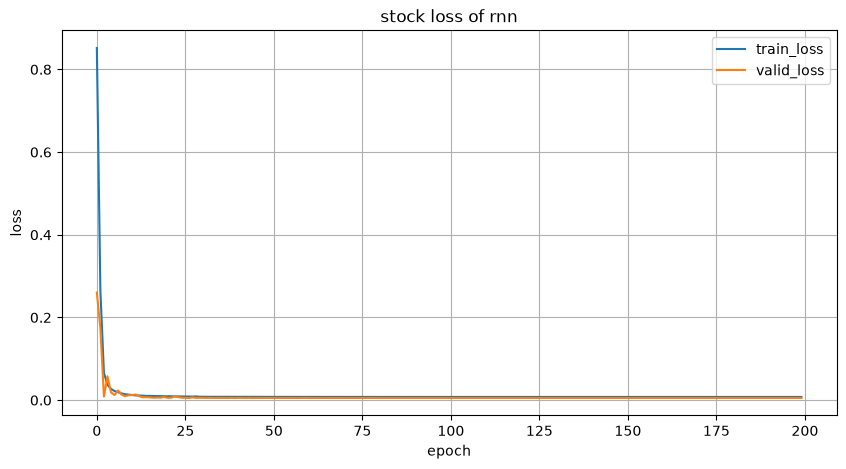

In [127]:
# 损失可视化
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="train_loss")
plt.plot(valid_losses, label="valid_loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("stock loss of rnn")
plt.legend()
plt.grid(True)
plt.show()

In [128]:
# 测试
test_model = YfinanceRNN(input_size=input_size, output_size=input_size).to(device)
test_model.load_state_dict(torch.load("../../data/output/yinanceRNN_best_model_state_dict.pt"))
test_model.eval()

test_loss_sum = 0.0
test_samples = 0

with torch.inference_mode():
    for x, y in test_loader:
        output = test_model(x)
        loss = criterion(output, y)
        test_loss_sum += loss.item() * x.size(0)
        test_samples += x.size(0)

test_loss = test_loss_sum / test_samples
print(f"test_loss: {test_loss}")


    # # 还原成真实价格
    # pred_prices = scaler.inverse_transform(pred)
    #
    # true_prices = scaler.inverse_transform(y_true)


test_loss: 0.0073356011084147865
